<a href="https://colab.research.google.com/github/sindhuraperii/Effect-of-Spatial-Filter-Size-on-Image-Quality/blob/main/1713_image_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ===== Step 1: Import the libraries =====
import numpy as np                                    # NumPy: arrays and random number generation
import cv2                                            # OpenCV: mean, Gaussian, and median filters
import pandas as pd                                   # pandas: stores the results in a table
import matplotlib.pyplot as plt                       # Matplotlib: draws images and graphs
from skimage import data                              # scikit-image: built-in sample images
from skimage.metrics import peak_signal_noise_ratio   # PSNR quality metric
from skimage.metrics import structural_similarity     # SSIM quality metric

In [ ]:
# ===== Step 2: Load the original image =====
original = data.camera()                              # load the 512x512 grayscale cameraman image (uint8, 0-255)
print("Image shape:", original.shape, "| dtype:", original.dtype)  # print the size and data type to confirm them

Image shape: (512, 512) | dtype: uint8


In [ ]:
# ===== Step 3: Create degraded (noisy) versions of the image =====
rng = np.random.default_rng(42)                       # random generator with a fixed seed so results are repeatable
sigma = 25                                            # standard deviation of the Gaussian noise (0-255 scale)
gauss = rng.normal(0, sigma, original.shape)          # one random noise value per pixel from a normal distribution
noisy = np.clip(original + gauss, 0, 255).astype(np.uint8)  # add the noise, keep values in 0-255, convert to 8-bit
sp = original.copy()                                  # copy the original so salt-and-pepper noise can be added
mask = rng.random(original.shape)                     # a random number between 0 and 1 for every pixel
sp[mask < 0.025] = 0                                  # set about 2.5% of pixels to black ("pepper")
sp[mask > 0.975] = 255                                # set about 2.5% of pixels to white ("salt")

In [ ]:
# ===== Step 4: Define the spatial filters and kernel sizes =====
filters = {                                           # dictionary mapping filter name to the function that applies it
    "Mean":     lambda img, k: cv2.blur(img, (k, k)),             # box filter: average of each k x k window
    "Gaussian": lambda img, k: cv2.GaussianBlur(img, (k, k), 0),  # weighted average that favors the center pixel
    "Median":   lambda img, k: cv2.medianBlur(img, k),            # replaces each pixel with the median of its window
}                                                     # end of the filter dictionary
kernel_sizes = [3, 5, 7, 9, 11, 15]                   # filter sizes to test: 3x3 up to 15x15 (odd sizes only)

In [ ]:
# ===== Step 5: Define the quality metrics =====
def sharpness(img):                                   # function that measures how much edge detail an image keeps
    lap = cv2.Laplacian(img, cv2.CV_64F)              # Laplacian: second-derivative response that highlights edges
    return lap.var()                                  # variance of the Laplacian: higher value = sharper image

def make_row(noise_name, f_name, k, img):             # helper that measures one output image and returns a table row
    return {                                          # the row is a dictionary of column values
        "Noise": noise_name,                          # type of noise in the input image
        "Filter": f_name,                             # filter applied ("None" for the noisy baseline)
        "Kernel": k,                                  # kernel size (0 for the baseline)
        "PSNR": peak_signal_noise_ratio(original, img, data_range=255),  # PSNR in dB: higher = closer to original
        "SSIM": structural_similarity(original, img, data_range=255),    # SSIM from -1 to 1: higher = more similar structure
        "Sharpness": sharpness(img),                  # edge detail remaining in the output image
    }                                                 # end of the row dictionary

In [ ]:
# ===== Step 6: Run the experiment =====
rows = []                                             # empty list that will hold one result row per experiment
noisy_versions = {"Gaussian noise": noisy, "Salt & pepper": sp}  # the two degraded images, labeled by noise type
for noise_name, degraded in noisy_versions.items():   # loop over each noisy image
    rows.append(make_row(noise_name, "None", 0, degraded))  # baseline: measure the noisy image with no filtering
    for f_name, f_func in filters.items():            # loop over each filter type
        for k in kernel_sizes:                        # loop over each kernel size
            filtered = f_func(degraded, k)            # apply the filter using a k x k window
            rows.append(make_row(noise_name, f_name, k, filtered))  # measure the result and store it
results = pd.DataFrame(rows)                          # convert the list of rows into a pandas table
results.round(3)                                      # display the table rounded to 3 decimal places

,Noise,Filter,Kernel,PSNR,SSIM,Sharpness
0,Gaussian noise,None,0,20.587,0.302,12385.436
1,Gaussian noise,Mean,3,26.592,0.579,302.815
2,Gaussian noise,Mean,5,25.890,0.652,66.577
3,Gaussian noise,Mean,7,24.709,0.656,24.813
4,Gaussian noise,Mean,9,23.732,0.638,12.620
5,Gaussian noise,Mean,11,23.004,0.620,7.819
6,Gaussian noise,Mean,15,22.092,0.599,4.165
7,Gaussian noise,Gaussian,3,26.918,0.577,331.582
8,Gaussian noise,Gaussian,5,27.194,0.648,91.812
9,Gaussian noise,Gaussian,7,26.629,0.688,28.021


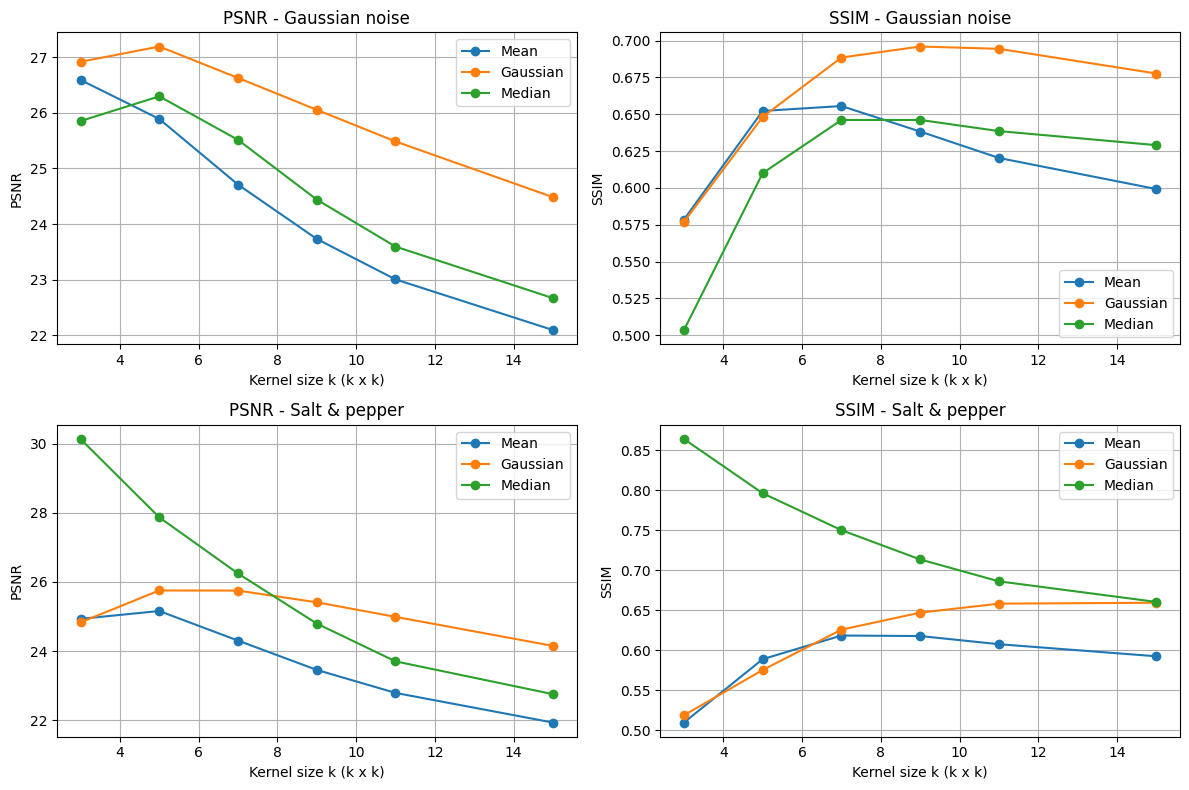

In [ ]:
# ===== Step 7: Plot PSNR and SSIM against kernel size =====
fig, axes = plt.subplots(2, 2, figsize=(12, 8))       # 2x2 grid: one row per noise type, one column per metric
for r, noise_name in enumerate(noisy_versions):       # loop over the noise types (one row of plots each)
    for c, metric in enumerate(["PSNR", "SSIM"]):    # loop over the metrics (one column each)
        ax = axes[r, c]                               # select the subplot at this row and column
        for f_name in filters:                        # draw one line per filter
            sub = results[(results["Noise"] == noise_name) & (results["Filter"] == f_name)]  # keep matching rows only
            ax.plot(sub["Kernel"], sub[metric], marker="o", label=f_name)  # plot the metric against kernel size
        ax.set_title(f"{metric} - {noise_name}")      # title for this subplot
        ax.set_xlabel("Kernel size k (k x k)")        # label for the x-axis
        ax.set_ylabel(metric)                         # label for the y-axis
        ax.legend()                                   # show which line belongs to which filter
        ax.grid(True)                                 # add grid lines to make values easier to read
plt.tight_layout()                                    # adjust spacing so labels do not overlap
plt.show()                                            # display the figure

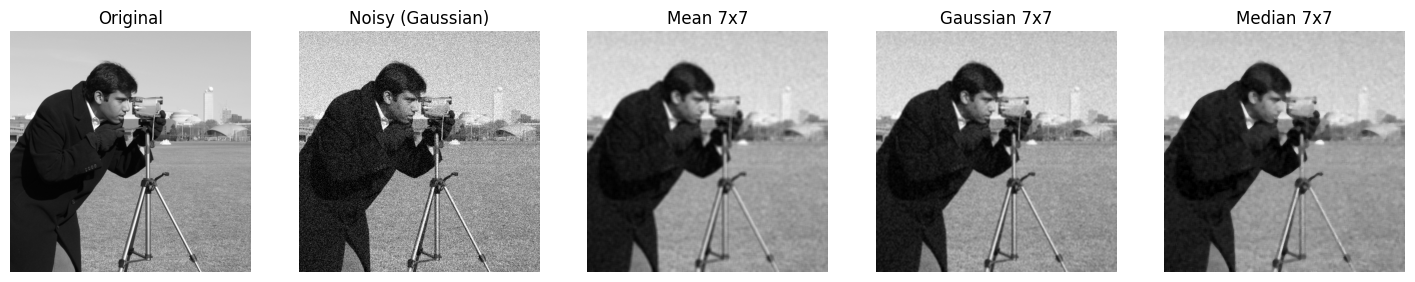

In [ ]:
# ===== Step 8: Visual comparison at one kernel size =====
k_show = 7                                            # kernel size used for the picture comparison
panels = [                                            # list of (title, image) pairs to display side by side
    ("Original", original),                           # the clean reference image
    ("Noisy (Gaussian)", noisy),                      # the image before any filtering
    (f"Mean {k_show}x{k_show}", cv2.blur(noisy, (k_show, k_show))),              # mean filter output
    (f"Gaussian {k_show}x{k_show}", cv2.GaussianBlur(noisy, (k_show, k_show), 0)),  # Gaussian filter output
    (f"Median {k_show}x{k_show}", cv2.medianBlur(noisy, k_show)),                # median filter output
]                                                     # end of the panel list
fig, axes = plt.subplots(1, len(panels), figsize=(18, 4))  # one row with one subplot per panel
for ax, (title, img) in zip(axes, panels):            # pair each subplot with its title and image
    ax.imshow(img, cmap="gray")                       # display the image in grayscale
    ax.set_title(title)                               # label the subplot
    ax.axis("off")                                    # hide the axis numbers for a cleaner view
plt.show()                                            # display the figure

In [ ]:
# ===== Step 9: Save the results for your report =====
results.to_csv("filter_size_results.csv", index=False)  # save the results table as a CSV file without the row index
from google.colab import files                        # Colab helper module for downloading files to your computer
files.download("filter_size_results.csv")             # download the CSV file so you can include it in your submission

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>